In [1]:
import sys
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

In [2]:
cwd = Path.cwd()
project_root = cwd.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
    print('Done!')

Done!


In [3]:
data_path = project_root / 'data' / 'processed' / 'demand_development.csv'
demand_data = pd.read_csv(data_path)

In [4]:
demand_data.head()

,timestamp_utc,interval_end_utc,timestamp_london,settlement_date,settlement_period,demand_mw,neso_day_ahead_forecast_mw,historic_nd_mw,historic_tsd_mw,forecast_issue_utc,...,match_id,opponent,scheduled_kickoff_utc,match_stage,event_role,temperature_london_c_retrospective,temperature_manchester_c_retrospective,temperature_birmingham_c_retrospective,temperature_proxy_c_retrospective,weather_ex_ante_eligible
0,2023-01-01 00:00:00+00:00,2023-01-01 00:30:00+00:00,2023-01-01 00:00:00+00:00,2023-01-01,1,20967,20320,21043,24680,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaN,NaN,NaN,11.60,9.00,9.1,9.900000,False
1,2023-01-01 00:30:00+00:00,2023-01-01 01:00:00+00:00,2023-01-01 00:30:00+00:00,2023-01-01,2,21699,20680,21756,25289,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaN,NaN,NaN,11.55,8.85,9.0,9.800000,False
2,2023-01-01 01:00:00+00:00,2023-01-01 01:30:00+00:00,2023-01-01 01:00:00+00:00,2023-01-01,3,21185,20498,21348,25269,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaN,NaN,NaN,11.50,8.70,8.9,9.700000,False
3,2023-01-01 01:30:00+00:00,2023-01-01 02:00:00+00:00,2023-01-01 01:30:00+00:00,2023-01-01,4,20442,19955,20586,24574,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaN,NaN,NaN,11.35,8.50,8.7,9.516667,False
4,2023-01-01 02:00:00+00:00,2023-01-01 02:30:00+00:00,2023-01-01 02:00:00+00:00,2023-01-01,5,19633,19512,19781,24135,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaN,NaN,NaN,11.20,8.30,8.5,9.333333,False


In [5]:
utc_columns = [
    'timestamp_utc',
    'interval_end_utc',
    'forecast_issue_utc',
    'forecast_cutoff_utc',
    'scheduled_kickoff_utc',
]

for column in utc_columns:
    demand_data[column] = pd.to_datetime(
        demand_data[column], utc=True
    )
    
demand_data['timestamp_london'] = (
    demand_data['timestamp_utc'].dt.tz_convert('Europe/London')
)


In [6]:
demand_data['settlement_date'] = pd.to_datetime(
    demand_data['settlement_date']
)

In [7]:
demand_data.columns

Index(['timestamp_utc', 'interval_end_utc', 'timestamp_london',
       'settlement_date', 'settlement_period', 'demand_mw',
       'neso_day_ahead_forecast_mw', 'historic_nd_mw', 'historic_tsd_mw',
       'forecast_issue_utc', 'forecast_cutoff_utc', 'neso_available_at_cutoff',
       'Datetime', 'Publish_Datetime', 'TRIAD_Avoidance_Estimate',
       'hour_of_week', 'half_hour_of_week', 'is_bank_holiday_england_wales',
       'is_bank_holiday_scotland', 'is_bank_holiday_any_gb', 'data_split',
       'baseline_fit_eligible', 'is_england_match_day', 'match_id', 'opponent',
       'scheduled_kickoff_utc', 'match_stage', 'event_role',
       'temperature_london_c_retrospective',
       'temperature_manchester_c_retrospective',
       'temperature_birmingham_c_retrospective',
       'temperature_proxy_c_retrospective', 'weather_ex_ante_eligible'],
      dtype='str')

In [8]:
train = demand_data.loc[
    demand_data['data_split'].eq('train')
].copy()

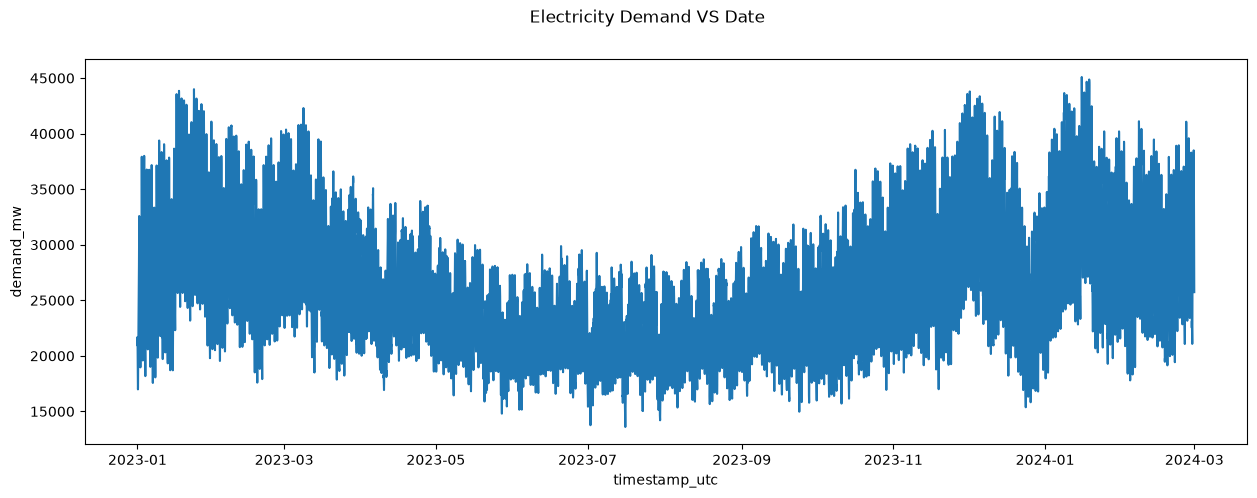

In [9]:
fig, ax = plt.subplots(figsize=(15, 5))

sns.lineplot(
    data=train,
    x='timestamp_utc',
    y='demand_mw',
    ax=ax
)

fig.suptitle('Electricity Demand VS Date')
plt.show()

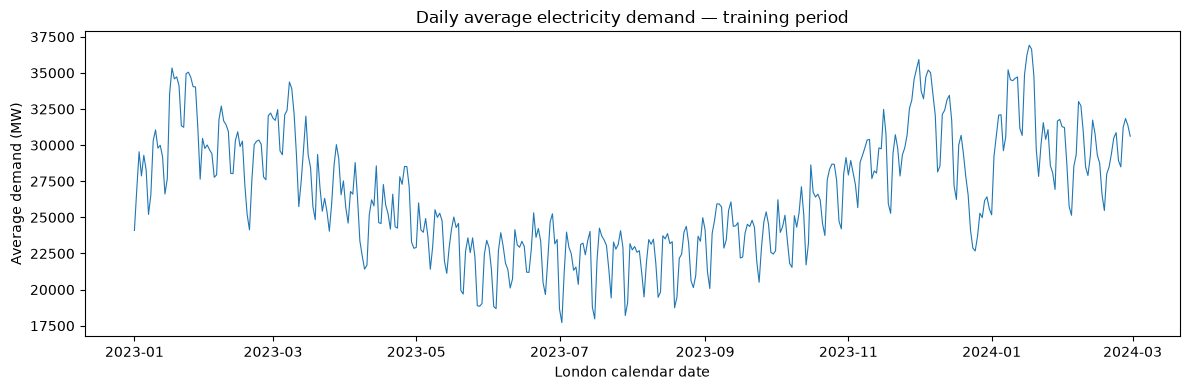

In [10]:
daily_mean = (
    train.groupby(by='settlement_date')['demand_mw']
    .mean()
)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(daily_mean.index, daily_mean.values, linewidth=0.8)
ax.set(
    title='Daily average electricity demand — training period',
    xlabel='London calendar date',
    ylabel='Average demand (MW)'
)

fig.tight_layout()
plt.show()

## One week of half-hourly demand

In [11]:
# Keep the training view explicitly aligned with the UTC timeline.
train['timestamp_london'] = (
    train['timestamp_utc'].dt.tz_convert('Europe/London')
)


In [12]:
train[['timestamp_utc', 'timestamp_london', 'demand_mw']].head()

,timestamp_utc,timestamp_london,demand_mw
0,2023-01-01 00:00:00+00:00,2023-01-01 00:00:00+00:00,20967
1,2023-01-01 00:30:00+00:00,2023-01-01 00:30:00+00:00,21699
2,2023-01-01 01:00:00+00:00,2023-01-01 01:00:00+00:00,21185
3,2023-01-01 01:30:00+00:00,2023-01-01 01:30:00+00:00,20442
4,2023-01-01 02:00:00+00:00,2023-01-01 02:00:00+00:00,19633


In [13]:
train['timestamp_london'].dtype

datetime64[us, Europe/London]

In [14]:
sample_week = (
    train
    .loc[
        (train['timestamp_london'] >= pd.Timestamp(
            year=2023,
            month=2,
            day=6,
            tz='Europe/London')) 
        & 
        (train['timestamp_london'] < pd.Timestamp(
            year=2023,
            month=2,
            day=13,
            tz='Europe/London'))
        ]
)[['timestamp_london', 'demand_mw']]

In [15]:
sample_week.head()

,timestamp_london,demand_mw
1728,2023-02-06 00:00:00+00:00,24417
1729,2023-02-06 00:30:00+00:00,24994
1730,2023-02-06 01:00:00+00:00,24359
1731,2023-02-06 01:30:00+00:00,24021
1732,2023-02-06 02:00:00+00:00,23683


In [16]:
sample_week.shape

(336, 2)

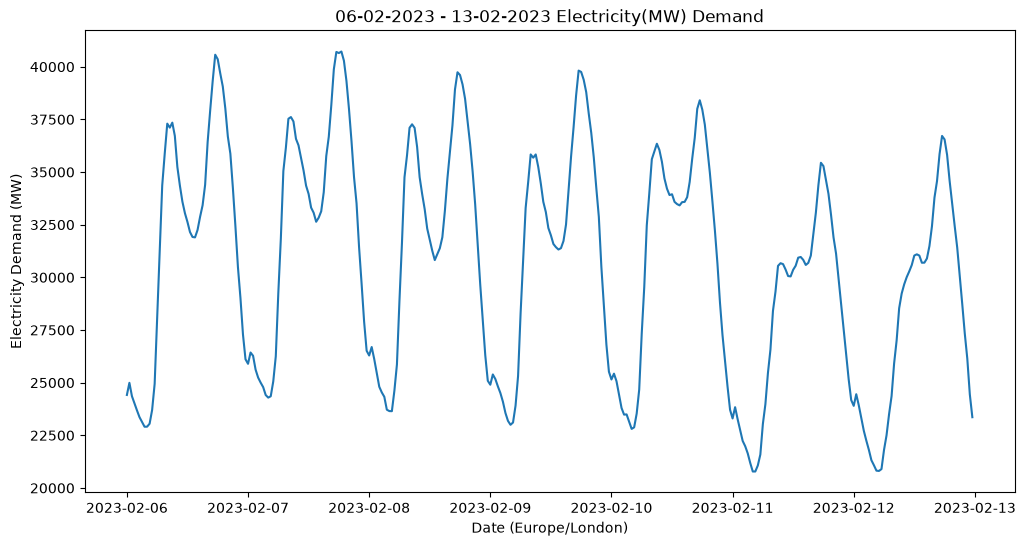

In [17]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(sample_week['timestamp_london'], sample_week['demand_mw'])

ax.set(
    title='06-02-2023 - 13-02-2023 Electricity(MW) Demand',
    xlabel='Date (Europe/London)',
    ylabel='Electricity Demand (MW)'
)

plt.show()

In [18]:
sample_week['timestamp_london'].min(), sample_week['timestamp_london'].max()

(Timestamp('2023-02-06 00:00:00+0000', tz='Europe/London'),
 Timestamp('2023-02-12 23:30:00+0000', tz='Europe/London'))

### Interpretation of the plot

##### Ob - 1
- Observation - Around 8-9 AM we get the first peak in the week days.
- Possible explaination - This peak may correspond to people morning routine waking up bathing, eating lunch etc.
- Limitaion - The exact timing cannot be deduced as the exact timings within a day is not mentioned in the plot.

##### Ob - 2
- Observation - Around exact afternoon we get the a dip in the demand.
- Possible explaination - This could be cause of all the people go out of home to work and all.
- Limitation - One thing to clarify here is that which electricity demand this daya includes.. just the household or what else.

##### Ob - 3
- Observation - Around 8-9 PM we get the another and higher peak in the demand.
- Possible explaination - This could because, People come back home and they start using all the appliances.. make dinner watch TV sports etc.
- Limitaion - Again the exact timing cannot be deduced and exact activities also cannnot we deduced and also why this peak is higher than the morning one is also a question to pondered upon.

##### Ob - 4
- Observation - The weekdays we can see on average the demand is higher compared to the weekends.
- Possible explaination - Cause weekends are holidays people most probabily go out for picnic or extra activities.
- Limitaion - Again we have to clarify which electricity demands this demand actually contains to concretely say the possibility

##### Ob - 5
- Observation - The morning peaks in the weekends almost disapears.
- Possible explaination - people party late and wake up late.. although in general people wake up late on the weekends.
- Limitation - Not sure of if the above is the only possible explaination there could be more

##### Ob - 6
- Observation - This one is weird if you see carefully, The is a tiny sudden spike in the curve around the midnight.
- Possible explaination - Idk honestly... could be anything.. any technical bug or reset spike or something..
- Limitaion - The above explaination is completely vague assumption,, or theory that i made up..

In [19]:
demand_data.loc[demand_data['baseline_fit_eligible']==True].shape

(19922, 33)

## Let's investigate if the patterns are relevant for more data

In [20]:
baseline_train = demand_data.loc[demand_data['baseline_fit_eligible']].copy()
baseline_train.head()

,timestamp_utc,interval_end_utc,timestamp_london,settlement_date,settlement_period,demand_mw,neso_day_ahead_forecast_mw,historic_nd_mw,historic_tsd_mw,forecast_issue_utc,...,match_id,opponent,scheduled_kickoff_utc,match_stage,event_role,temperature_london_c_retrospective,temperature_manchester_c_retrospective,temperature_birmingham_c_retrospective,temperature_proxy_c_retrospective,weather_ex_ante_eligible
0,2023-01-01 00:00:00+00:00,2023-01-01 00:30:00+00:00,2023-01-01 00:00:00+00:00,2023-01-01,1,20967,20320,21043,24680,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.60,9.00,9.1,9.900000,False
1,2023-01-01 00:30:00+00:00,2023-01-01 01:00:00+00:00,2023-01-01 00:30:00+00:00,2023-01-01,2,21699,20680,21756,25289,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.55,8.85,9.0,9.800000,False
2,2023-01-01 01:00:00+00:00,2023-01-01 01:30:00+00:00,2023-01-01 01:00:00+00:00,2023-01-01,3,21185,20498,21348,25269,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.50,8.70,8.9,9.700000,False
3,2023-01-01 01:30:00+00:00,2023-01-01 02:00:00+00:00,2023-01-01 01:30:00+00:00,2023-01-01,4,20442,19955,20586,24574,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.35,8.50,8.7,9.516667,False
4,2023-01-01 02:00:00+00:00,2023-01-01 02:30:00+00:00,2023-01-01 02:00:00+00:00,2023-01-01,5,19633,19512,19781,24135,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.20,8.30,8.5,9.333333,False


In [21]:
baseline_train = (
    baseline_train
    .assign(
        weekday=lambda r: r['timestamp_london'].dt.day_of_week
    )
)

In [22]:
baseline_train['weekday'].unique()

array([6, 0, 1, 2, 3, 4, 5], dtype=int32)

In [23]:
baseline_train = (
    baseline_train
    .assign(
        half_hour_slot=lambda r: (r['timestamp_london'].dt.hour * 2) + (r['timestamp_london'].dt.minute // 30)
    )
)

In [24]:
baseline_train['half_hour_slot'].unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47],
      dtype=int32)

In [25]:
baseline_train.columns

Index(['timestamp_utc', 'interval_end_utc', 'timestamp_london',
       'settlement_date', 'settlement_period', 'demand_mw',
       'neso_day_ahead_forecast_mw', 'historic_nd_mw', 'historic_tsd_mw',
       'forecast_issue_utc', 'forecast_cutoff_utc', 'neso_available_at_cutoff',
       'Datetime', 'Publish_Datetime', 'TRIAD_Avoidance_Estimate',
       'hour_of_week', 'half_hour_of_week', 'is_bank_holiday_england_wales',
       'is_bank_holiday_scotland', 'is_bank_holiday_any_gb', 'data_split',
       'baseline_fit_eligible', 'is_england_match_day', 'match_id', 'opponent',
       'scheduled_kickoff_utc', 'match_stage', 'event_role',
       'temperature_london_c_retrospective',
       'temperature_manchester_c_retrospective',
       'temperature_birmingham_c_retrospective',
       'temperature_proxy_c_retrospective', 'weather_ex_ante_eligible',
       'weekday', 'half_hour_slot'],
      dtype='str')

In [26]:
summary_data = (
    baseline_train
    .groupby(by=['weekday', 'half_hour_slot'], as_index=False)
    .agg(
        mean_demand = ('demand_mw', 'mean'),
        count = ('demand_mw', 'count')
    )
)

In [27]:
summary_data.head()

,weekday,half_hour_slot,mean_demand,count
0,0,0,21043.033898,59
1,0,1,21110.406780,59
2,0,2,20820.542373,59
3,0,3,20541.288136,59
4,0,4,20196.915254,59


In [28]:
summary_data.columns

Index(['weekday', 'half_hour_slot', 'mean_demand', 'count'], dtype='str')

In [29]:
summary_data['weekday'] = summary_data['weekday'].replace({
    0 : 'Monday',
    1 : 'Tuesday',
    2 : 'Wednesday',
    3 : 'Thursday',
    4 : 'Friday',
    5 : 'Saturday',
    6 : 'Sunday'
})

In [30]:
summary_data['hour'] = summary_data['half_hour_slot'] / 2

In [31]:
summary_data.head()

,weekday,half_hour_slot,mean_demand,count,hour
0,Monday,0,21043.033898,59,0.0
1,Monday,1,21110.406780,59,0.5
2,Monday,2,20820.542373,59,1.0
3,Monday,3,20541.288136,59,1.5
4,Monday,4,20196.915254,59,2.0


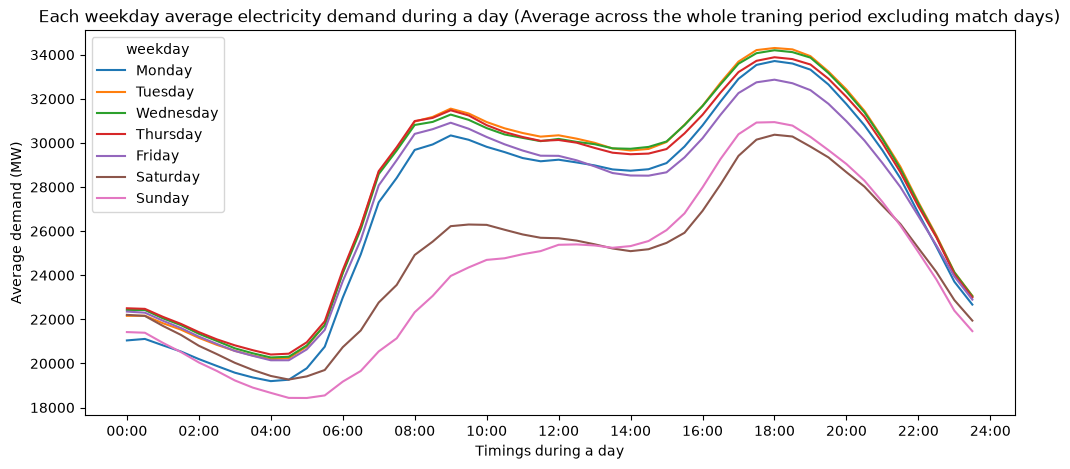

In [32]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(
    data=summary_data,
    x='hour',
    y='mean_demand',
    ax=ax,
    hue='weekday'
)

ax.set_xticks(range(0, 25, 2))
ax.set_xticklabels([f'{h:02d}:00' for h in range(0, 25, 2)])

ax.set(
    title='Each weekday average electricity demand during a day (Average across the whole traning period excluding match days)',
    xlabel='Timings during a day',
    ylabel='Average demand (MW)'
)

plt.show()

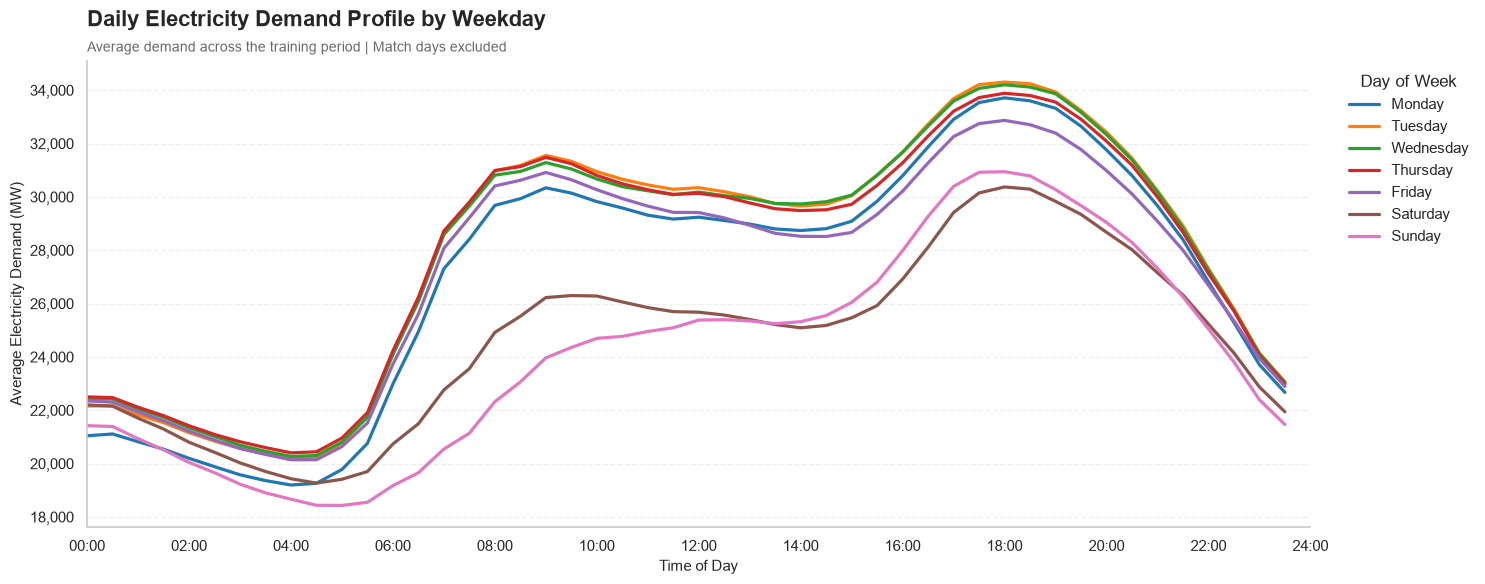

In [33]:
weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

# Styling
sns.set_theme(style='whitegrid', context='notebook')

fig, ax = plt.subplots(figsize=(15, 6))

sns.lineplot(
    data=summary_data,
    x='hour',
    y='mean_demand',
    hue='weekday',
    hue_order=weekday_order,
    palette='tab10',
    linewidth=2.3,
    estimator=None,
    ax=ax
)

# X-axis formatting
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 2))
ax.set_xticklabels(
    [f'{h:02d}:00' for h in range(0, 25, 2)]
)

# Y-axis formatting
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

# Titles and labels
ax.set_title(
    'Daily Electricity Demand Profile by Weekday',
    fontsize=16,
    fontweight='bold',
    loc='left',
    pad=25
)

ax.text(
    0, 1.02,
    'Average demand across the training period | Match days excluded',
    transform=ax.transAxes,
    fontsize=10,
    color='dimgray'
)

ax.set_xlabel('Time of Day', fontsize=11)
ax.set_ylabel('Average Electricity Demand (MW)', fontsize=11)

# Minimal grid
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.grid(axis='x', visible=False)

# Remove unnecessary borders
sns.despine(ax=ax)

# Legend outside the plot
ax.legend(
    title='Day of Week',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=False
)

plt.tight_layout()
plt.show()

## How much do individual days vary around the average curve?

In [34]:
monday = baseline_train.loc[baseline_train['weekday'] == 0]

In [35]:
mon_spread = (
    monday
    .groupby(by=['half_hour_slot'], as_index=False)
    .agg(
        median=('demand_mw', 'median'),
        p25=('demand_mw', lambda x: x.quantile(0.25)),
        p75=('demand_mw', lambda x: x.quantile(0.75)),
        count=('demand_mw', 'count')
    )
)

In [36]:
mon_spread['hour'] = mon_spread['half_hour_slot'].divide(2)

In [37]:
mon_spread.head()

,half_hour_slot,median,p25,p75,count,hour
0,0,20752.0,19093.0,22713.5,59,0.0
1,1,20948.0,18775.0,23021.0,59,0.5
2,2,20726.0,18327.5,22694.0,59,1.0
3,3,20666.0,18289.5,22390.0,59,1.5
4,4,20498.0,17957.5,22095.5,59,2.0


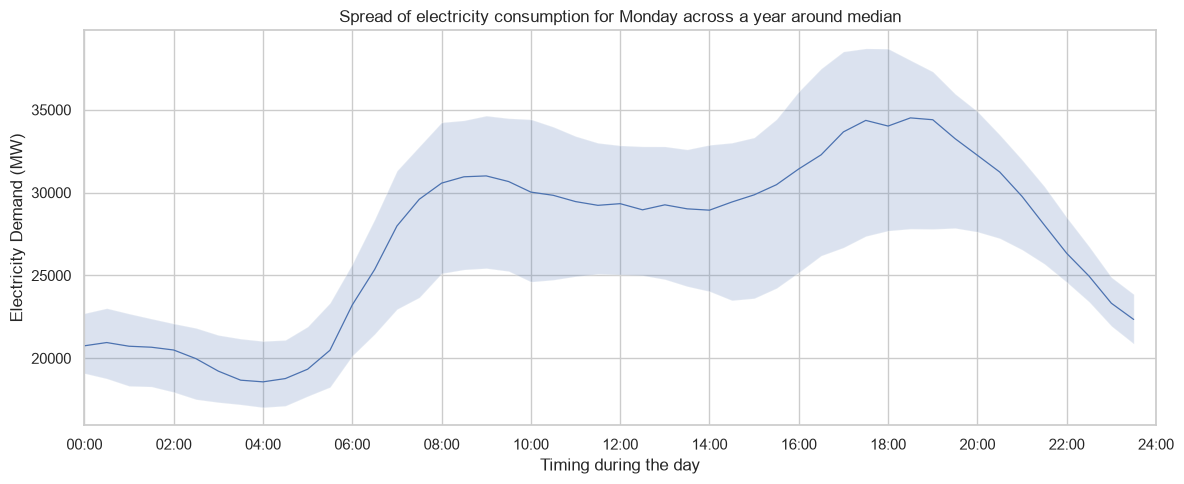

In [38]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    mon_spread['hour'],
    mon_spread['median'],
    linewidth=0.9
)

ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 2))
ax.set_xticklabels(
    [f'{h:02d}:00' for h in range(0, 25, 2)]
)

ax.fill_between(
    mon_spread['hour'],
    mon_spread['p25'],
    mon_spread['p75'],
    alpha=0.2
)

ax.set(
    title="Spread of electricity consumption for Monday across a year around median",
    xlabel='Timing during the day',
    ylabel='Electricity Demand (MW)'
)

plt.tight_layout()
plt.show()

In [39]:
mon_spread['iqr'] = mon_spread['p75'] - mon_spread['p25']

mon_spread.loc[
    [mon_spread['iqr'].idxmin(), mon_spread['iqr'].idxmax()],
    ['hour', 'p25', 'p75', 'iqr']
]

,hour,p25,p75,iqr
46,23.0,21947.0,24892.0,2945.0
34,17.0,26687.5,38520.5,11833.0


## Let's do for friday, sunday and saturday

### Friday

In [40]:
fri = baseline_train.loc[baseline_train['weekday'] == 4]

In [41]:
fri_spread = (
    fri
    .groupby(by=['half_hour_slot'], as_index=False)
    .agg(
        median=('demand_mw', 'median'),
        p25=('demand_mw', lambda x: x.quantile(0.25)),
        p75=('demand_mw', lambda x: x.quantile(0.75)),
        count=('demand_mw', 'count')
    )
)

In [42]:
fri_spread['hour'] = fri_spread['half_hour_slot'].divide(2)

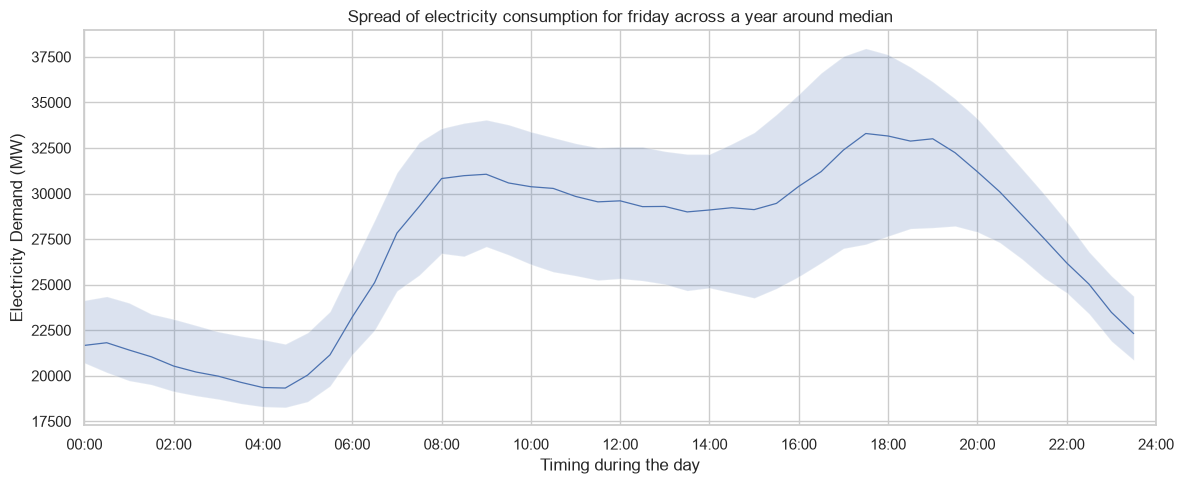

In [43]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    fri_spread['hour'],
    fri_spread['median'],
    linewidth=0.9
)

ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 2))
ax.set_xticklabels(
    [f'{h:02d}:00' for h in range(0, 25, 2)]
)

ax.fill_between(
    fri_spread['hour'],
    fri_spread['p25'],
    fri_spread['p75'],
    alpha=0.2
)

ax.set(
    title="Spread of electricity consumption for friday across a year around median",
    xlabel='Timing during the day',
    ylabel='Electricity Demand (MW)'
)

plt.tight_layout()
plt.show()

### Saturday

In [44]:
sat = baseline_train.loc[baseline_train['weekday'] == 5]

In [45]:
sat_spread = (
    sat
    .groupby(by=['half_hour_slot'], as_index=False)
    .agg(
        median=('demand_mw', 'median'),
        p25=('demand_mw', lambda x: x.quantile(0.25)),
        p75=('demand_mw', lambda x: x.quantile(0.75)),
        count=('demand_mw', 'count')
    )
)

In [46]:
sat_spread['hour'] = sat_spread['half_hour_slot'].divide(2)

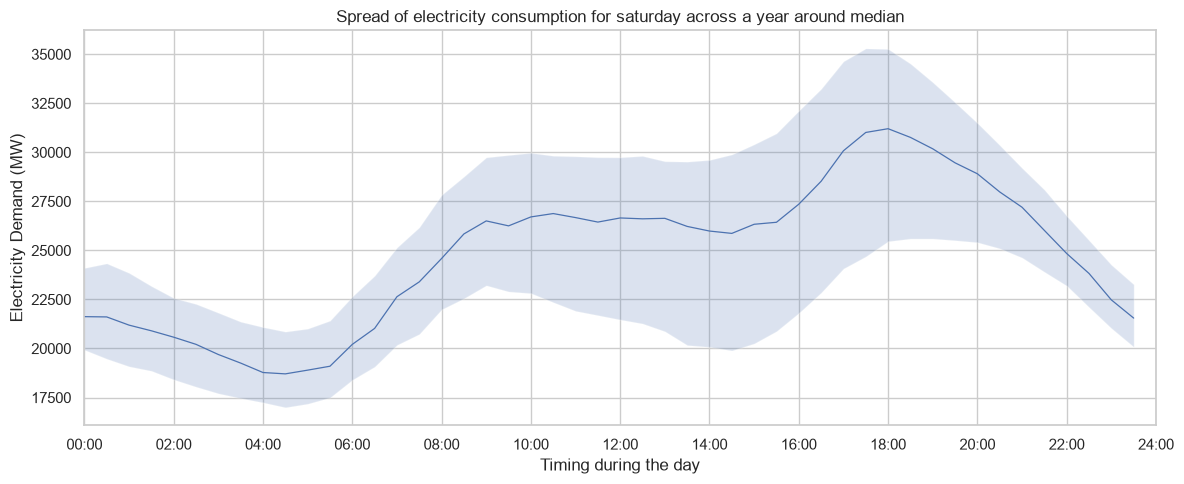

In [47]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    sat_spread['hour'],
    sat_spread['median'],
    linewidth=0.9
)

ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 2))
ax.set_xticklabels(
    [f'{h:02d}:00' for h in range(0, 25, 2)]
)

ax.fill_between(
    sat_spread['hour'],
    sat_spread['p25'],
    sat_spread['p75'],
    alpha=0.2
)

ax.set(
    title="Spread of electricity consumption for saturday across a year around median",
    xlabel='Timing during the day',
    ylabel='Electricity Demand (MW)'
)

plt.tight_layout()
plt.show()

## Winter-vs-Summer weekday and weekend comparison

#### Monday

In [67]:
seasonal_mondays = monday.copy()

In [68]:
winter_months = ['December', 'January', 'February']
summer_months = ['June', 'July', 'August']

In [69]:
def check_season(month: str) -> str | None:
    if month in winter_months:
        return 'Winter'
    elif month in summer_months:
        return 'Summer'
    else:
        return None

In [70]:
seasonal_mondays = (
    seasonal_mondays
    .assign(
        season=lambda d: d['timestamp_london'].dt.month_name().apply(check_season)
    )
)

In [72]:
seasonal_mondays.dropna(subset=['season'], inplace=True)

In [75]:
summer = seasonal_mondays.loc[seasonal_mondays['season'] == 'Summer']
winter = seasonal_mondays.loc[seasonal_mondays['season'] == 'Winter']

In [77]:
print(f"Distinct settlement dates in summer: {len(summer['settlement_date'].unique())}")
print(f"Distinct settlement dates in winter: {len(winter['settlement_date'].unique())}")

Distinct settlement dates in summer: 12
Distinct settlement dates in winter: 22


In [82]:
seasonal_summary = (
    seasonal_mondays
    .groupby(by=['season', 'half_hour_slot'], as_index=False)
    .agg(
        median=('demand_mw', 'median'),
        p25=('demand_mw', lambda d: np.quantile(d, q=0.25)),
        p75=('demand_mw', lambda d: np.quantile(d, q=0.75)),
        count=('demand_mw', 'count'),
    )
)

In [85]:
seasonal_summary['hour'] = seasonal_summary['half_hour_slot'].divide(2)

In [86]:
seasonal_summary.head()

,season,half_hour_slot,median,p25,p75,count,hour
0,Summer,0,18715.5,18470.25,19055.50,12,0.0
1,Summer,1,18273.0,18084.50,18637.25,12,0.5
2,Summer,2,17920.0,17805.50,18214.25,12,1.0
3,Summer,3,17685.5,17488.25,17884.00,12,1.5
4,Summer,4,17374.0,17131.25,17617.75,12,2.0


In [87]:
summer_summary = seasonal_summary.loc[seasonal_summary['season'] == 'Summer']
winter_summary = seasonal_summary.loc[seasonal_summary['season'] == 'Winter']

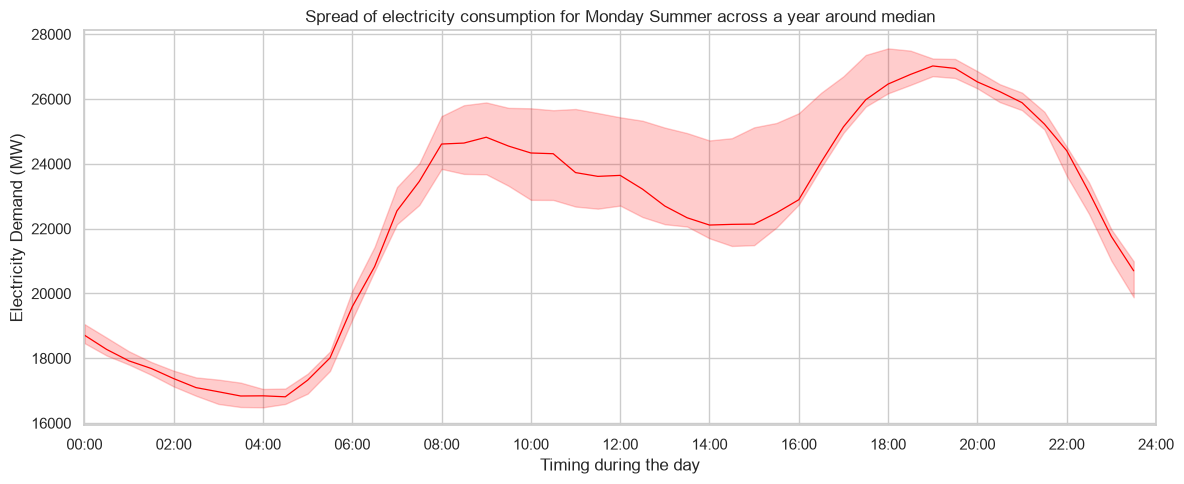

In [94]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    summer_summary['hour'],
    summer_summary['median'],
    linewidth=0.9,
    color='red'
)

ax.fill_between(
    summer_summary['hour'],
    summer_summary['p25'],
    summer_summary['p75'],
    alpha=0.2,
    color='red'
)

ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 2))
ax.set_xticklabels(
    [f'{h:02d}:00' for h in range(0, 25, 2)]
)

ax.set(
    title="Spread of electricity consumption for Monday Summer across a year around median",
    xlabel='Timing during the day',
    ylabel='Electricity Demand (MW)'
)

plt.tight_layout()
plt.show()

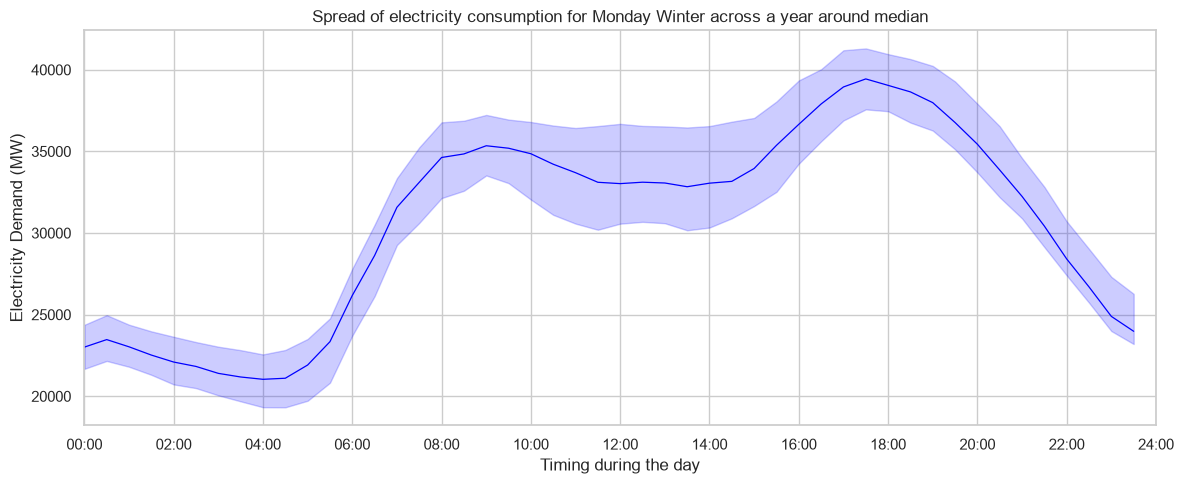

In [95]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    winter_summary['hour'],
    winter_summary['median'],
    linewidth=0.9,
    color='blue'
)

ax.fill_between(
    winter_summary['hour'],
    winter_summary['p25'],
    winter_summary['p75'],
    alpha=0.2,
    color='blue'
)

ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 2))
ax.set_xticklabels(
    [f'{h:02d}:00' for h in range(0, 25, 2)]
)

ax.set(
    title="Spread of electricity consumption for Monday Winter across a year around median",
    xlabel='Timing during the day',
    ylabel='Electricity Demand (MW)'
)

plt.tight_layout()
plt.show()

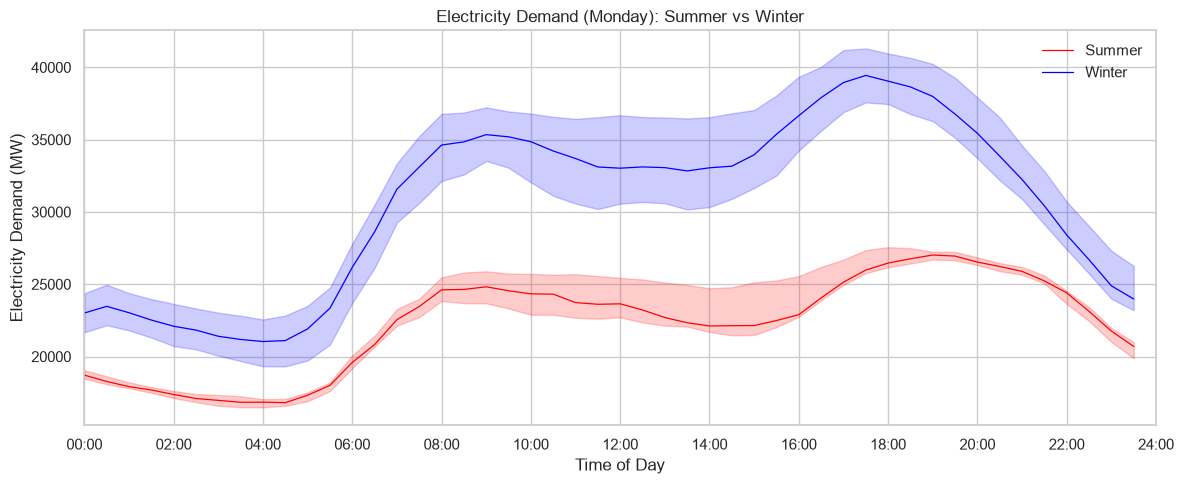

In [96]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    summer_summary['hour'],
    summer_summary['median'],
    linewidth=0.9,
    color='red',
    label='Summer'
)

ax.fill_between(
    summer_summary['hour'],
    summer_summary['p25'],
    summer_summary['p75'],
    alpha=0.2,
    color='red'
)

ax.plot(
    winter_summary['hour'],
    winter_summary['median'],
    linewidth=0.9,
    color='blue',
    label='Winter'
)

ax.fill_between(
    winter_summary['hour'],
    winter_summary['p25'],
    winter_summary['p75'],
    alpha=0.2,
    color='blue'
)

ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 2))
ax.set_xticklabels(
    [f'{h:02d}:00' for h in range(0, 25, 2)]
)

ax.set(
    title="Electricity Demand (Monday): Summer vs Winter",
    xlabel='Time of Day',
    ylabel='Electricity Demand (MW)'
)

ax.legend(loc='upper right', frameon=False)

plt.tight_layout()
plt.show()

- Separating winter and summer reveals differences in both demand level and daily shape. At 17:00, within-season IQRs are substantially smaller than the pooled Monday IQR. This suggests seasonal mixing contributes to the pooled spread, while considerable variation remains within winter.